# 04 – Descriptive analysis (research questions 1 and 2)

**Inputs:** `data/processed/ctgov_analysis_dataset.parquet` (7,960 trials, start 2005–2022,
Completed or Terminated) and `data/processed/why_stopped_final.parquet` (final termination
reasons, D41).

| Part | Content | Block |
|---|---|---|
| A | Overall termination rate, termination reasons, healthy volunteers vs. patients | B11 |
| B | Terminations by indication, country, sponsor type and year | B12 |

All shares are given with **95 % confidence intervals (Wilson score interval)**.

In [1]:
# --- Setup -------------------------------------------------------------------
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency
from statsmodels.stats.proportion import proportion_confint

import viz_style as vs

vs.apply()
pd.set_option("display.width", 160)

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED = PROJECT_DIR / "data" / "processed"
FIGURES = PROJECT_DIR / "figures"
DATA_NOTE = "Source: ClinicalTrials.gov API v2, data as of 27 Oct 2026 · Phase 1 and 1/2 · start 2005–2022 · " \
            "≥1 site in UK, DE, FR, ES, NL, BE or IT"

data = pd.read_parquet(PROCESSED / "ctgov_analysis_dataset.parquet")
reasons = pd.read_parquet(PROCESSED / "why_stopped_final.parquet")
data = data.merge(reasons[["nct_id", "primary_reason_final", "safety_related_final", "reason_source"]],
                  on="nct_id", how="left")
data["safety_termination"] = data["safety_related_final"].fillna(0).astype(int)
assert data.loc[data["terminated"] == 1, "primary_reason_final"].notna().all()
assert data.loc[data["terminated"] == 0, "primary_reason_final"].isna().all()
print(f"{len(data):,} trials | {data['terminated'].sum():,} terminated | "
      f"{data['safety_termination'].sum()} safety-related terminations")


def share_ci(k, n):
    """Share in % with 95% Wilson CI as (estimate, lower, upper)."""
    lo, hi = proportion_confint(k, n, method="wilson")
    return 100 * k / n, 100 * lo, 100 * hi


def fmt(k, n):
    p, lo, hi = share_ci(k, n)
    return f"{p:.1f} % ({lo:.1f}–{hi:.1f})"

7,960 trials | 1,154 terminated | 109 safety-related terminations


## Part A – Research question 1

### A1. Overall termination rate

In [2]:
n_all, n_term = len(data), int(data["terminated"].sum())
n_safe = int(data["safety_termination"].sum())
print(f"Terminated                     : {n_term:,} / {n_all:,} = {fmt(n_term, n_all)}")
print(f"Safety-related terminations    : {n_safe} / {n_all:,} = {fmt(n_safe, n_all)} of all trials")
print(f"                                 {n_safe} / {n_term:,} = {fmt(n_safe, n_term)} of terminated trials")

Terminated                     : 1,154 / 7,960 = 14.5 % (13.7–15.3)
Safety-related terminations    : 109 / 7,960 = 1.4 % (1.1–1.6) of all trials
                                 109 / 1,154 = 9.4 % (7.9–11.3) of terminated trials


### A2. Termination reasons

Final labels (D41): expert classification for the 252 reviewed trials, rule-based algorithm (v2)
for all others. One **primary reason** per trial (priority: Safety > Efficacy/Futility >
COVID-19 > Recruitment > Funding > Strategic/Business > Sponsor decision > Other > Not stated).

**Uncertainty note:** the Safety share is robust (all algorithm-Safety texts were reviewed by the
expert). The shares of the other categories rest on the algorithm plus a random review sample of
60 texts and are less certain – e.g. for **Efficacy/Futility** the algorithm (v1) gave 9.4 %,
while the weighted expert estimate from the validation sample was 15.3 %. The confidence intervals
below only reflect sampling variation of the trials, not this classification uncertainty.

In [3]:
CATEGORIES = ["Safety", "Efficacy/Futility", "COVID-19", "Recruitment", "Funding", "Strategic/Business",
              "Sponsor decision (unspecified)", "Other", "Not stated"]
term = data[data["terminated"] == 1]
counts = term["primary_reason_final"].value_counts().reindex(CATEGORIES, fill_value=0)
rows = []
for cat, k in counts.items():
    p_t, lo_t, hi_t = share_ci(k, n_term)
    p_a, lo_a, hi_a = share_ci(k, n_all)
    rows.append({"primary reason": cat, "trials": int(k),
                 "% of terminated": round(p_t, 1), "95% CI (terminated)": f"{lo_t:.1f}–{hi_t:.1f}",
                 "% of all trials": round(p_a, 2), "95% CI (all)": f"{lo_a:.2f}–{hi_a:.2f}"})
reason_table = pd.DataFrame(rows).sort_values("trials", ascending=False).reset_index(drop=True)
reason_table.to_csv(PROCESSED / "table_termination_reasons.csv", index=False)
reason_table

,primary reason,trials,% of terminated,95% CI (terminated),% of all trials,95% CI (all)
0,Strategic/Business,301,26.1,23.6–28.7,3.78,3.38–4.22
1,Other,193,16.7,14.7–19.0,2.42,2.11–2.79
2,Recruitment,152,13.2,11.3–15.2,1.91,1.63–2.23
3,Not stated,143,12.4,10.6–14.4,1.80,1.53–2.11
4,Efficacy/Futility,116,10.1,8.4–11.9,1.46,1.22–1.74
5,Safety,109,9.4,7.9–11.3,1.37,1.14–1.65
6,Sponsor decision (unspecified),98,8.5,7.0–10.2,1.23,1.01–1.50
7,COVID-19,26,2.3,1.5–3.3,0.33,0.22–0.48
8,Funding,16,1.4,0.9–2.2,0.20,0.12–0.33


Saved figure: 02_termination_reasons.png


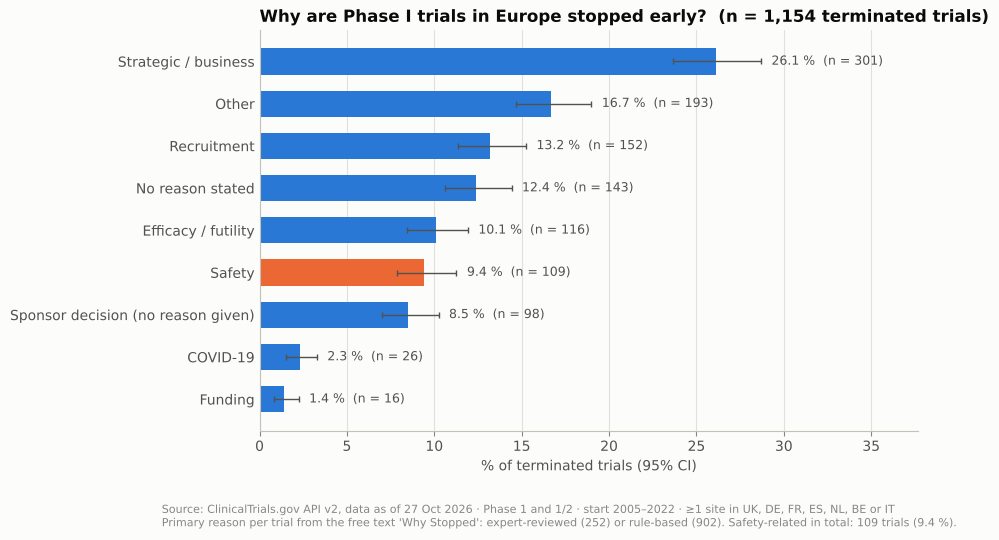

In [4]:
# Figure: why are Phase I trials stopped early? (share of terminated trials, 95% CI)
SHORT = {"Sponsor decision (unspecified)": "Sponsor decision (no reason given)",
         "Not stated": "No reason stated", "Strategic/Business": "Strategic / business",
         "Efficacy/Futility": "Efficacy / futility"}
plot_df = reason_table.sort_values("% of terminated")
labels = [SHORT.get(c, c) for c in plot_df["primary reason"]]
est = plot_df["% of terminated"].to_numpy()
ci = np.array([share_ci(k, n_term)[1:] for k in plot_df["trials"]])
colors = [vs.SERIES[1] if c == "Safety" else vs.SERIES[0] for c in plot_df["primary reason"]]

fig, ax = plt.subplots(figsize=(8.5, 5.2))
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.barh(labels, est, color=colors, height=0.62, zorder=2)
ax.errorbar(est, labels, xerr=[est - ci[:, 0], ci[:, 1] - est], fmt="none",
            ecolor=vs.INK_SECONDARY, elinewidth=1, capsize=2.5, zorder=3)
for y, (e, hi, n) in enumerate(zip(est, ci[:, 1], plot_df["trials"])):
    ax.text(hi + 0.6, y, f"{e:.1f} %  (n = {n})", va="center", fontsize=9, color=vs.INK_SECONDARY)
ax.set_xlim(0, max(ci[:, 1]) + 9)
ax.set_xlabel("% of terminated trials (95% CI)")
ax.set_title(f"Why are Phase I trials in Europe stopped early?  (n = {n_term:,} terminated trials)")
ax.tick_params(axis="y", length=0)
vs.source_note(fig, DATA_NOTE + "\nPrimary reason per trial from the free text 'Why Stopped': expert-reviewed "
               "(252) or rule-based (902). Safety-related in total: "
               f"{n_safe} trials ({share_ci(n_safe, n_term)[0]:.1f} %).", y=-0.03)
vs.save(fig, FIGURES / "02_termination_reasons.png")
plt.show()

### A3. Healthy volunteers vs. patients (with and without oncology, D32)

Oncology is a third of the dataset, has the highest termination share and almost no
healthy-volunteer trials. The comparison is therefore repeated **without oncology** to check that
the difference is not only an oncology effect. A further row restricts to trials started
2005–2019 (less right-censoring, D26).

* **Terminated %** – share of all trials in the group that were terminated
* **Safety-related termination %** – share of all trials in the group terminated for a
  safety-related reason
* **Safety share of terminations** – share of terminated trials with a safety-related reason

In [5]:
def group_stats(df, label):
    out = []
    for hv, name in [(1, "Healthy volunteers"), (0, "Patients")]:
        g = df[df["healthy_volunteers"] == hv]
        n, t, s = len(g), int(g["terminated"].sum()), int(g["safety_termination"].sum())
        out.append({"subset": label, "population": name, "trials": n, "terminated": t,
                    "terminated %": fmt(t, n), "safety-related termination %": fmt(s, n),
                    "safety share of terminations": fmt(s, t) if t else "–",
                    "_t": share_ci(t, n), "_s": share_ci(s, n)})
    tab = pd.crosstab(df["healthy_volunteers"], df["terminated"])
    p_val = chi2_contingency(tab)[1]
    for r in out:
        r["p (chi², terminated)"] = f"{p_val:.1e}"
    return out


non_onc = data["indication_group"] != "Oncology"
subsets = [("All indications", data), ("Excluding oncology", data[non_onc]),
           ("All indications, start 2005–2019", data[data["start_year"] <= 2019]),
           ("Excluding oncology, start 2005–2019", data[non_onc & (data["start_year"] <= 2019)])]
hv_rows = [r for label, df in subsets for r in group_stats(df, label)]
hv_table = pd.DataFrame(hv_rows)
hv_table.drop(columns=["_t", "_s"]).to_csv(PROCESSED / "table_hv_vs_patients.csv", index=False)
hv_table.drop(columns=["_t", "_s"])

,subset,population,trials,terminated,terminated %,safety-related termination %,safety share of terminations,"p (chi², terminated)"
0,All indications,Healthy volunteers,3718,240,6.5 % (5.7–7.3),0.9 % (0.6–1.2),13.3 % (9.6–18.2),6.8e-81
1,All indications,Patients,4242,914,21.5 % (20.3–22.8),1.8 % (1.5–2.3),8.4 % (6.8–10.4),6.8e-81
2,Excluding oncology,Healthy volunteers,3633,231,6.4 % (5.6–7.2),0.9 % (0.6–1.2),13.4 % (9.6–18.4),1.1e-18
3,Excluding oncology,Patients,1647,227,13.8 % (12.2–15.5),1.0 % (0.6–1.6),7.5 % (4.7–11.7),1.1e-18
4,"All indications, start 2005–2019",Healthy volunteers,3089,182,5.9 % (5.1–6.8),0.8 % (0.5–1.2),13.2 % (9.0–18.9),1.1e-52
5,"All indications, start 2005–2019",Patients,3651,669,18.3 % (17.1–19.6),1.6 % (1.3–2.1),9.0 % (7.0–11.4),1.1e-52
6,"Excluding oncology, start 2005–2019",Healthy volunteers,3034,175,5.8 % (5.0–6.7),0.8 % (0.5–1.1),13.1 % (8.9–18.9),2.2e-13
7,"Excluding oncology, start 2005–2019",Patients,1435,174,12.1 % (10.5–13.9),0.9 % (0.5–1.5),7.5 % (4.4–12.4),2.2e-13


Saved figure: 03_healthy_volunteers_vs_patients.png


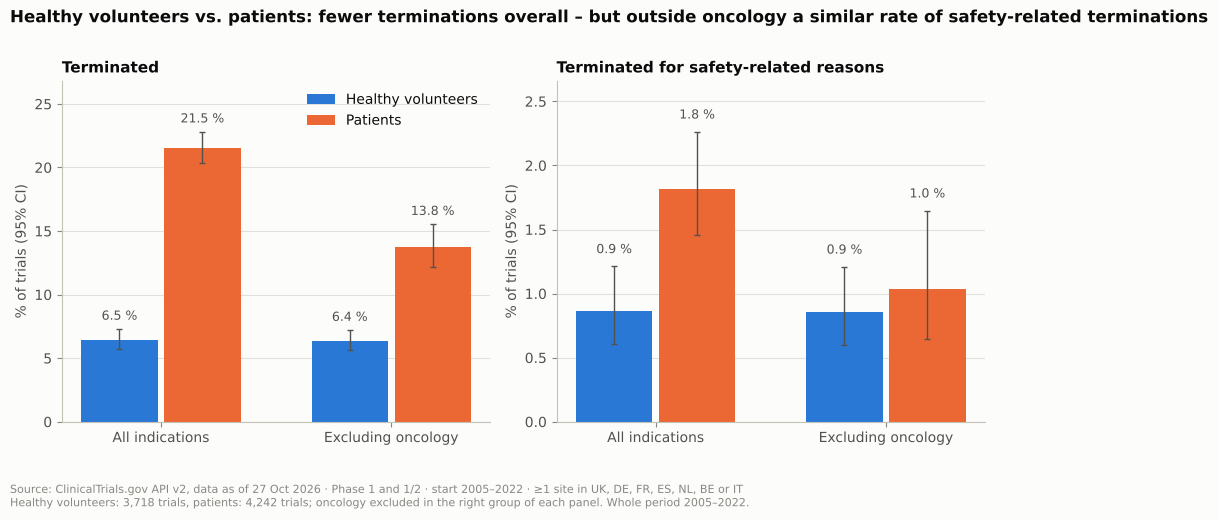

In [6]:
# Figure: healthy volunteers vs. patients – all indications and excluding oncology (two panels, own axes)
plot_rows = hv_table[hv_table["subset"].isin(["All indications", "Excluding oncology"])]
groups = ["All indications", "Excluding oncology"]
pops = [("Healthy volunteers", vs.SERIES[0]), ("Patients", vs.SERIES[1])]
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6))
for ax, metric, title in [(axes[0], "_t", "Terminated"), (axes[1], "_s", "Terminated for safety-related reasons")]:
    x = np.arange(len(groups))
    width = 0.36
    for i, (pop, color) in enumerate(pops):
        vals = [plot_rows[(plot_rows["subset"] == g) & (plot_rows["population"] == pop)][metric].iloc[0] for g in groups]
        est_ = np.array([v[0] for v in vals]); lo_ = np.array([v[1] for v in vals]); hi_ = np.array([v[2] for v in vals])
        xs = x + (i - 0.5) * width
        ax.bar(xs, est_, width=width * 0.92, color=color, label=pop, zorder=2)
        ax.errorbar(xs, est_, yerr=[est_ - lo_, hi_ - est_], fmt="none", ecolor=vs.INK_SECONDARY,
                    elinewidth=1, capsize=2.5, zorder=3)
        for xx, e, h in zip(xs, est_, hi_):
            ax.text(xx, h + (0.5 if metric == "_t" else 0.08), f"{e:.1f} %", ha="center", va="bottom",
                    fontsize=9, color=vs.INK_SECONDARY)
    ax.set_xticks(x, groups)
    ax.set_ylabel("% of trials (95% CI)")
    ax.set_title(title, fontsize=11)
    ax.set_ylim(0, ax.get_ylim()[1] * 1.12)
axes[0].legend(loc="upper right")
fig.suptitle("Healthy volunteers vs. patients: fewer terminations overall – but outside oncology "
             "a similar rate of safety-related terminations",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
n_hv = int(data["healthy_volunteers"].sum())
vs.source_note(fig, DATA_NOTE + f"\nHealthy volunteers: {n_hv:,} trials, patients: {n_all - n_hv:,} trials; "
               "oncology excluded in the right group of each panel. Whole period 2005–2022.", y=-0.05)
fig.tight_layout(rect=(0, 0, 1, 0.97))
vs.save(fig, FIGURES / "03_healthy_volunteers_vs_patients.png")
plt.show()

### A4. Summary of Part A

**Research question 1 – how many Phase I trials are terminated, and why?**

* **14.5 %** of the 7,960 Phase I trials (start 2005–2022, sites in UK/DE/FR/ES/NL/BE/IT) were
  terminated (95 % CI 13.7–15.3 %).
* **Safety-related terminations: 109** – 9.4 % of terminated trials (7.9–11.3 %) or **1.4 % of all
  trials** (1.1–1.6 %).
* Most terminations have business or non-transparent reasons: strategic/business 26.1 %, no reason
  stated 12.4 %, sponsor decision without reason 8.5 % – together **47 %**.
* Classification uncertainty: the Safety share is expert-validated; shares of the other
  categories are less certain (e.g. Efficacy/Futility: algorithm 9.4 % vs. weighted expert
  estimate 15.3 % in the validation sample).

**Healthy volunteers vs. patients (D32)**

| | Healthy volunteers | Patients |
|---|---|---|
| Terminated – all indications | 6.5 % (5.7–7.3) | 21.5 % (20.3–22.8) |
| Terminated – excluding oncology | 6.4 % (5.6–7.2) | 13.8 % (12.2–15.5) |
| Safety-related termination – all indications | 0.9 % (0.6–1.2) | 1.8 % (1.5–2.3) |
| Safety-related termination – excluding oncology | 0.9 % (0.6–1.2) | 1.0 % (0.6–1.6) |
| Safety share of terminations – all indications | 13.3 % (9.6–18.2) | 8.4 % (6.8–10.4) |

* Healthy-volunteer trials are terminated much less often. Without oncology the difference is
  roughly halved but remains clear (6.4 % vs. 13.8 %) – it is **not only an oncology effect**.
* For **safety-related** terminations the picture differs: the higher rate in patient trials is
  essentially an **oncology effect** – outside oncology the rates are similar (0.9 % vs. 1.0 %,
  overlapping CIs).
* When a healthy-volunteer trial is terminated, safety is somewhat more often the reason (13.3 %
  vs. 8.4 % of terminations) – based on 32 trials, wide CI.
* Results hold for trials started 2005–2019 (less right-censoring).

## Part B – Research question 2: indication, country, sponsor type, start year

Groups with **fewer than 100 trials** are flagged (`small group`) and should not be
over-interpreted; all shares carry 95 % Wilson CIs.

In [7]:
SMALL_N = 100


def rate_table(df, by, label=None):
    rows = []
    for val, g in df.groupby(by, observed=True):
        n, t, s = len(g), int(g["terminated"].sum()), int(g["safety_termination"].sum())
        p_t, lo_t, hi_t = share_ci(t, n)
        p_s, lo_s, hi_s = share_ci(s, n)
        rows.append({label or by: val, "trials": n, "terminated": t,
                     "terminated %": round(p_t, 1), "CI low": round(lo_t, 1), "CI high": round(hi_t, 1),
                     "safety-related": s, "safety-related %": round(p_s, 2),
                     "safety CI": f"{lo_s:.2f}–{hi_s:.2f}",
                     "healthy volunteers %": round(100 * g["healthy_volunteers"].mean(), 1),
                     "note": "small group" if n < SMALL_N else ""})
    return pd.DataFrame(rows)


def dot_plot(tab, label_col, title, path, note, extra=None):
    """Horizontal dot plot of terminated % with 95% CI, sorted; optional second series."""
    tab = tab.sort_values("terminated %")
    fig, ax = plt.subplots(figsize=(8.5, 0.48 * len(tab) + 1.8))
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", visible=True)
    y = np.arange(len(tab))
    ax.hlines(y, tab["CI low"], tab["CI high"], color=vs.SERIES[0], lw=2, zorder=2)
    ax.plot(tab["terminated %"], y, "o", color=vs.SERIES[0], markersize=8, zorder=3,
            label=extra[0] if extra else None)
    if extra:
        ex = extra[1].set_index(label_col).reindex(tab[label_col])
        ax.hlines(y - 0.22, ex["CI low"], ex["CI high"], color=vs.SERIES[1], lw=2, zorder=2)
        ax.plot(ex["terminated %"], y - 0.22, "o", mfc=vs.SURFACE, mec=vs.SERIES[1], mew=2, markersize=7,
                zorder=3, label=extra[2])
        ax.legend(loc="lower right")
    overall = 100 * n_term / n_all
    ax.axvline(overall, color=vs.INK_MUTED, lw=1, ls="--", zorder=1)
    ax.text(overall, -0.75, f" overall {overall:.1f} %", color=vs.INK_MUTED, fontsize=8.5, va="center")
    ax.set_ylim(-1.1, len(tab) - 0.5)
    if extra:
        n_extra = extra[1].set_index(label_col).reindex(tab[label_col])["trials"].to_numpy()
        labels = [f"{v}  (n = {n:,} / {m:,})" for v, n, m in zip(tab[label_col], tab["trials"], n_extra)]
    else:
        labels = [f"{v}  (n = {n:,}){' *' if n < SMALL_N else ''}" for v, n in zip(tab[label_col], tab["trials"])]
    ax.set_yticks(y, labels)
    ax.tick_params(axis="y", length=0)
    ax.set_xlim(0, max(tab["CI high"].max(), extra[1]["CI high"].max() if extra else 0) * 1.08)
    ax.set_xlabel("% of trials terminated (95% CI)")
    ax.set_title(title)
    vs.source_note(fig, DATA_NOTE + "\n" + note, y=-0.02)
    vs.save(fig, path)
    return fig

### B1. By indication group

In [8]:
ind = rate_table(data, "indication_group", "indication group").sort_values("terminated %", ascending=False)
ind.to_csv(PROCESSED / "table_by_indication.csv", index=False)
ind

,indication group,trials,terminated,terminated %,CI low,CI high,safety-related,safety-related %,safety CI,healthy volunteers %,note
6,Oncology,2680,696,26.0,24.3,27.7,61,2.28,1.78–2.91,3.2,
2,Immunology & inflammation,425,64,15.1,12.0,18.8,7,1.65,0.80–3.36,35.3,
5,Nervous system & mental disorders,733,94,12.8,10.6,15.4,8,1.09,0.55–2.14,50.2,
7,Other diseases,539,61,11.3,8.9,14.3,7,1.30,0.63–2.66,46.8,
0,Cardiovascular,258,29,11.2,7.9,15.7,3,1.16,0.40–3.36,42.2,
3,Infectious diseases & vaccines,661,55,8.3,6.4,10.7,7,1.06,0.51–2.17,74.9,
8,Respiratory,351,26,7.4,5.1,10.6,2,0.57,0.16–2.05,65.5,
4,Metabolic & endocrine,522,35,6.7,4.9,9.2,1,0.19,0.03–1.08,47.5,
1,Healthy volunteers – no target condition,1791,94,5.2,4.3,6.4,13,0.73,0.42–1.24,99.4,


Saved figure: 04_terminations_by_indication.png


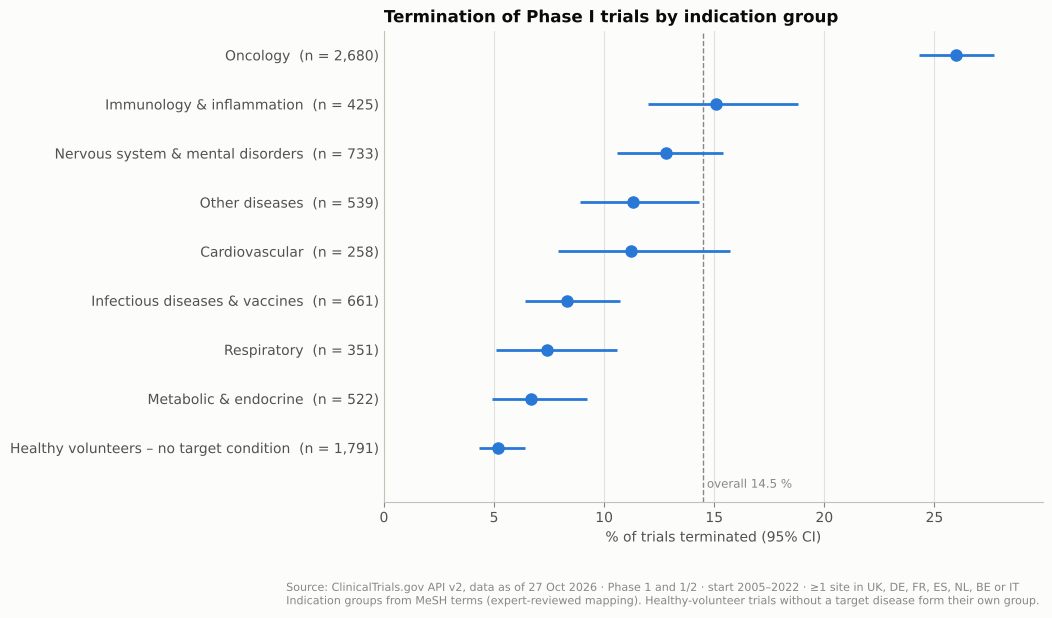

In [9]:
dot_plot(ind, "indication group", "Termination of Phase I trials by indication group",
         FIGURES / "04_terminations_by_indication.png",
         "Indication groups from MeSH terms (expert-reviewed mapping). Healthy-volunteer trials "
         "without a target disease form their own group.")
plt.show()

### B2. By country

A trial with sites in several of the seven countries is **counted once for each of these countries**
(multi-country counting – the country rows therefore add up to more than 7,960 trials). For
comparison, the hollow markers show **single-country trials only** (sites in exactly one country
overall), where every trial is counted once.

In [10]:
TARGET = ["United Kingdom", "Germany", "France", "Spain", "Netherlands", "Belgium", "Italy"]
long = data.assign(country=data["target_countries"].str.split("|")).explode("country")
long = long[long["country"].isin(TARGET)]
by_country = rate_table(long, "country")
single = data[data["n_countries"] == 1].assign(country=lambda d: d["target_countries"])
by_country_single = rate_table(single[single["country"].isin(TARGET)], "country")
cmp_country = by_country.merge(by_country_single[["country", "trials", "terminated %", "CI low", "CI high"]],
                               on="country", suffixes=("", " (single-country)"))
print(f"Country rows (multi-country counting): {by_country['trials'].sum():,} for {len(data):,} trials")
cmp_country.sort_values("terminated %", ascending=False).to_csv(PROCESSED / "table_by_country.csv", index=False)
cmp_country.sort_values("terminated %", ascending=False)

Country rows (multi-country counting): 11,092 for 7,960 trials


,country,trials,terminated,terminated %,CI low,CI high,safety-related,safety-related %,safety CI,healthy volunteers %,note,trials (single-country),terminated % (single-country),CI low (single-country),CI high (single-country)
3,Italy,735,201,27.3,24.2,30.7,14,1.90,1.14–3.17,3.7,,120,15.8,10.4,23.4
5,Spain,1382,360,26.0,23.8,28.4,28,2.03,1.41–2.91,8.3,,307,8.8,6.1,12.5
1,France,1537,338,22.0,20.0,24.1,31,2.02,1.42–2.85,16.7,,565,12.9,10.4,15.9
4,Netherlands,1147,189,16.5,14.4,18.7,20,1.74,1.13–2.68,38.6,,595,8.7,6.7,11.3
0,Belgium,1200,187,15.6,13.6,17.7,16,1.33,0.82–2.15,48.4,,614,6.5,4.8,8.7
6,United Kingdom,2853,423,14.8,13.6,16.2,40,1.40,1.03–1.90,52.3,,1817,9.2,8.0,10.7
2,Germany,2238,301,13.4,12.1,14.9,17,0.76,0.47–1.21,42.3,,1357,8.1,6.8,9.7


Saved figure: 05_terminations_by_country.png


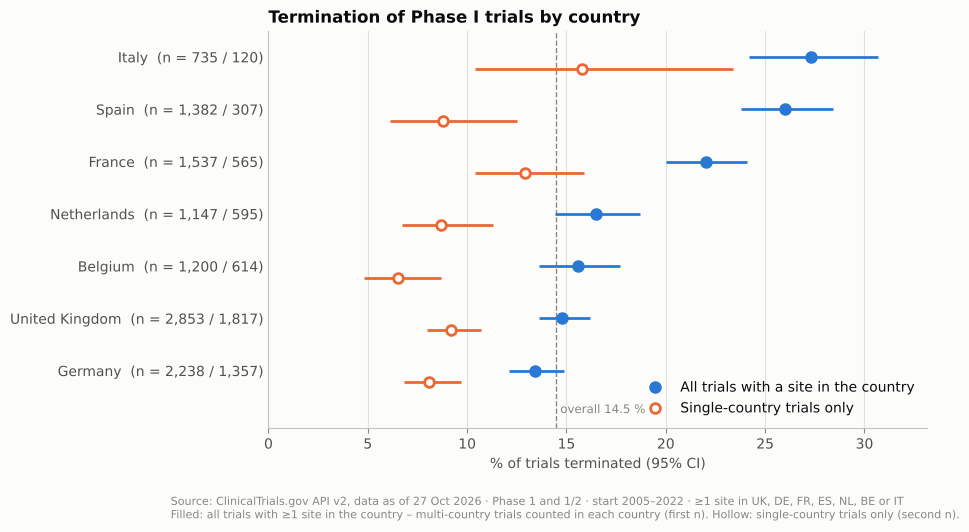

In [11]:
dot_plot(by_country, "country", "Termination of Phase I trials by country",
         FIGURES / "05_terminations_by_country.png",
         "Filled: all trials with ≥1 site in the country – multi-country trials counted in each country "
         "(first n). Hollow: single-country trials only (second n).",
         extra=("All trials with a site in the country", by_country_single, "Single-country trials only"))
plt.show()

### B3. By sponsor type

Shown overall and separately for healthy-volunteer and patient trials, because industry sponsors run
most healthy-volunteer trials (a confounder for the crude comparison).

In [12]:
sp_all = rate_table(data, "sponsor_group", "sponsor").assign(population="All")
sp_hv = rate_table(data[data["healthy_volunteers"] == 1], "sponsor_group", "sponsor").assign(population="Healthy volunteers")
sp_pt = rate_table(data[data["healthy_volunteers"] == 0], "sponsor_group", "sponsor").assign(population="Patients")
sponsor = pd.concat([sp_all, sp_hv, sp_pt])[["population", "sponsor", "trials", "terminated %", "CI low", "CI high",
                                             "safety-related %", "safety CI", "healthy volunteers %", "note"]]
sponsor.to_csv(PROCESSED / "table_by_sponsor.csv", index=False)
sponsor

,population,sponsor,trials,terminated %,CI low,CI high,safety-related %,safety CI,healthy volunteers %,note
0,All,Academic / other,1630,13.7,12.1,15.4,1.78,1.24–2.54,31.9,
1,All,Government / network / other,76,7.9,3.7,16.2,1.32,0.23–7.08,31.6,small group
2,All,Industry,6254,14.8,13.9,15.7,1.26,1.01–1.57,50.8,
0,Healthy volunteers,Academic / other,520,7.1,5.2,9.7,1.35,0.65–2.75,100.0,
1,Healthy volunteers,Government / network / other,24,0.0,0.0,13.8,0.00,0.00–13.80,100.0,small group
2,Healthy volunteers,Industry,3174,6.4,5.6,7.3,0.79,0.53–1.16,100.0,
0,Patients,Academic / other,1110,16.8,14.7,19.1,1.98,1.31–2.98,0.0,
1,Patients,Government / network / other,52,11.5,5.4,23.0,1.92,0.34–10.12,0.0,small group
2,Patients,Industry,3080,23.4,22.0,25.0,1.75,1.35–2.28,0.0,


### B4. By start year (descriptive only)

Markers: TGN1412 (March 2006), EMA first-in-human guideline (2007), BIA 10-2474 (January 2016),
revised EMA first-in-human guideline (published 2017, effective 2018). Start years from 2019 are
shaded: many of these trials were still running at data cut-off, and terminated trials reach a
final status earlier than completed ones – their termination share is biased upwards
(right-censoring, D26). **No trend test here**; this is addressed in Block 14.

In [13]:
yr = rate_table(data, "start_year", "start year")
yr.to_csv(PROCESSED / "table_by_start_year.csv", index=False)
yr[["start year", "trials", "terminated", "terminated %", "CI low", "CI high", "safety-related", "safety-related %", "safety CI"]]

,start year,trials,terminated,terminated %,CI low,CI high,safety-related,safety-related %,safety CI
0,2005,152,14,9.2,5.6,14.9,1,0.66,0.12–3.63
1,2006,200,20,10.0,6.6,14.9,1,0.50,0.09–2.78
2,2007,290,25,8.6,5.9,12.4,5,1.72,0.74–3.97
3,2008,349,27,7.7,5.4,11.0,2,0.57,0.16–2.07
4,2009,474,49,10.3,7.9,13.4,5,1.05,0.45–2.45
5,2010,515,47,9.1,6.9,11.9,10,1.94,1.06–3.54
6,2011,520,44,8.5,6.4,11.2,4,0.77,0.30–1.96
7,2012,503,51,10.1,7.8,13.1,3,0.60,0.20–1.74
8,2013,511,57,11.2,8.7,14.2,5,0.98,0.42–2.27
9,2014,592,65,11.0,8.7,13.8,13,2.20,1.29–3.72


Saved figure: 06_terminations_by_start_year.png


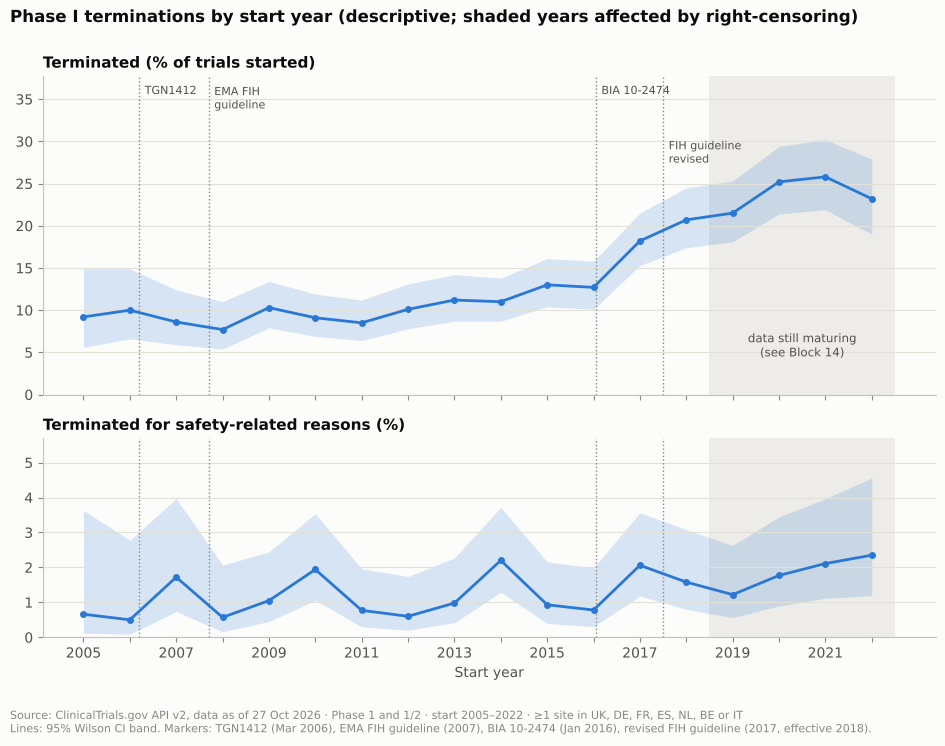

In [14]:
years = yr["start year"].astype(int).to_numpy()
fig, axes = plt.subplots(2, 1, figsize=(9.5, 7), sharex=True, gridspec_kw={"height_ratios": [1.6, 1]})
s_ci = np.array([share_ci(s, n)[1:] for s, n in zip(yr["safety-related"], yr["trials"])])
panels = [(axes[0], yr["terminated %"], yr["CI low"], yr["CI high"], "Terminated (% of trials started)"),
          (axes[1], yr["safety-related %"], s_ci[:, 0], s_ci[:, 1], "Terminated for safety-related reasons (%)")]
for ax, est_, lo_, hi_, title in panels:
    ax.axvspan(2018.5, 2022.5, color=vs.GRID, alpha=0.55, zorder=0, lw=0)
    ax.fill_between(years, lo_, hi_, color=vs.SERIES[0], alpha=0.18, lw=0, zorder=1)
    ax.plot(years, est_, color=vs.SERIES[0], marker="o", markersize=4, zorder=3)
    ax.set_title(title, fontsize=11)
    ax.set_ylim(0, max(hi_) * 1.25)
    for x_, txt, ypos in [(2006.2, "TGN1412", 0.97), (2007.7, "EMA FIH\nguideline", 0.97),
                          (2016.05, "BIA 10-2474", 0.97), (2017.5, "FIH guideline\nrevised", 0.80)]:
        ax.axvline(x_, color=vs.INK_MUTED, lw=1, ls=":", zorder=2)
        if ax is axes[0]:
            ax.text(x_ + 0.12, ax.get_ylim()[1] * ypos, txt, fontsize=8, color=vs.INK_SECONDARY, va="top")
axes[0].text(2020.5, axes[0].get_ylim()[1] * 0.12, "data still maturing\n(see Block 14)", ha="center",
             fontsize=8.5, color=vs.INK_SECONDARY)
axes[1].set_xticks(range(2005, 2023, 1), [str(y) if y % 2 == 1 else "" for y in range(2005, 2023)])
axes[1].set_xlabel("Start year")
fig.suptitle("Phase I terminations by start year (descriptive; shaded years affected by right-censoring)",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
vs.source_note(fig, DATA_NOTE + "\nLines: 95% Wilson CI band. Markers: TGN1412 (Mar 2006), EMA FIH guideline "
               "(2007), BIA 10-2474 (Jan 2016), revised FIH guideline (2017, effective 2018).", y=-0.02)
fig.tight_layout(rect=(0, 0, 1, 0.98))
vs.save(fig, FIGURES / "06_terminations_by_start_year.png")
plt.show()

### B5. Summary of Part B (descriptive)

**Indication:** oncology has by far the highest termination share (26.0 %, 95 % CI 24.3–27.7),
healthy-volunteer trials without a target disease the lowest (5.2 %, 4.3–6.4). Safety-related
terminations are highest in oncology (2.3 %); in all other groups they range from 0.2 % to 1.7 %
with overlapping CIs – group sizes are too small for a ranking.

**Country (multi-country trials counted in each country):** Italy, Spain and France show high
shares (27 %, 26 %, 22 %), but for **single-country trials** the shares are much lower and closer
together (6.5–15.8 %; Italy only 120 trials, wide CI). The country differences mainly reflect the
**trial mix**: in Italy and Spain few trials involve healthy volunteers (4 % and 8 %) and many are
multinational patient (often oncology) trials, whereas in the UK and Belgium about half are
healthy-volunteer trials. The figures are therefore **not** a measure of national performance.

**Sponsor type:** crude shares are similar (industry 14.8 %, academic 13.7 %). Stratified by
population, industry patient trials are terminated more often than academic ones (23.4 % vs.
16.8 %), while healthy-volunteer trials do not differ (6.4 % vs. 7.1 %). The
government/network group is small (76 trials) – not interpreted.

**Start year (descriptive only):** 8–13 % for trials started 2005–2016, then a rise to 18 % (2017),
21 % (2018) and about 25 % (2020–2021). The rise starts **before** the years most affected by
right-censoring, so it is probably not only an artefact; changes in the trial mix (e.g. more
oncology and multinational trials) are possible explanations. Safety-related terminations per
start year fluctuate between 0.5 % and 2.4 % with wide CIs and no visible change around 2016.
The pre/post comparison with adjustment and sensitivity analyses follows in Blocks 13–14.